In [1]:
from pathlib import Path
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure relative file paths work from the project root
if Path.cwd().name == "notebooks":
    os.chdir("..")

print("Working directory configured.")

Working directory configured.


In [2]:
cityflyer = pd.read_csv(
    "data/processed/ba_cityflyer_2019_2026.csv",
    parse_dates=["date"]
)

print("Dataset shape:", cityflyer.shape)

display(cityflyer.head())

Dataset shape: (91, 19)


,rundate,reporting_period,type_of_operations,airline_name,aircraft_km_x1000,no_flights,aircraft_hours,total_passengers_uplifted,seat_km_available_x1000,seat_km_used_x1000,cargo_tonnes_uplifted,total_tonne_km_available_x1000,tot_mail_tonne_km_used_x1000,total_freight_tonne_km_used_x1000,total_passenger_tonne_km_used_x1000,load_factor_pct,date,passengers_per_flight,avg_flight_distance_km
0,07/03/2019 11:11,201901,Passenger,BA CITYFLYER LTD,2027,3059,4376,174199,189033,118930,0,18903,0,0,10381,62.914941,2019-01-01,56.946388,662.634848
1,7/12/2019 4:50:06 AM,201902,Passenger,BA CITYFLYER LTD,2168,3334,4792,204657,199610,138504,0,19969,0,0,12038,69.387305,2019-02-01,61.384823,650.269946
2,6/14/2019 4:06:46 PM,201903,Passenger,BA CITYFLYER LTD,2447,3683,5407,235098,225254,161667,0,22547,0,0,14026,71.770979,2019-03-01,63.833288,664.404018
3,7/12/2019 5:04:07 AM,201904,Passenger,BA CITYFLYER LTD,2363,3551,5143,226066,218022,154725,0,21824,0,0,13478,70.967609,2019-04-01,63.662630,665.446353
4,8/20/2019 9:45:48 AM,201905,Passenger,BA CITYFLYER LTD,2795,3922,5929,256239,258281,187885,0,25855,0,0,16404,72.744414,2019-05-01,65.333758,712.646609


In [3]:
cityflyer = cityflyer.sort_values("date").reset_index(drop=True)

print("First month:", cityflyer["date"].min())
print("Last month:", cityflyer["date"].max())

print(
    "Missing passenger values:",
    cityflyer["total_passengers_uplifted"].isna().sum()
)

print("Duplicate dates:", cityflyer["date"].duplicated().sum())

First month: 2019-01-01 00:00:00
Last month: 2026-07-01 00:00:00
Missing passenger values: 0
Duplicate dates: 0


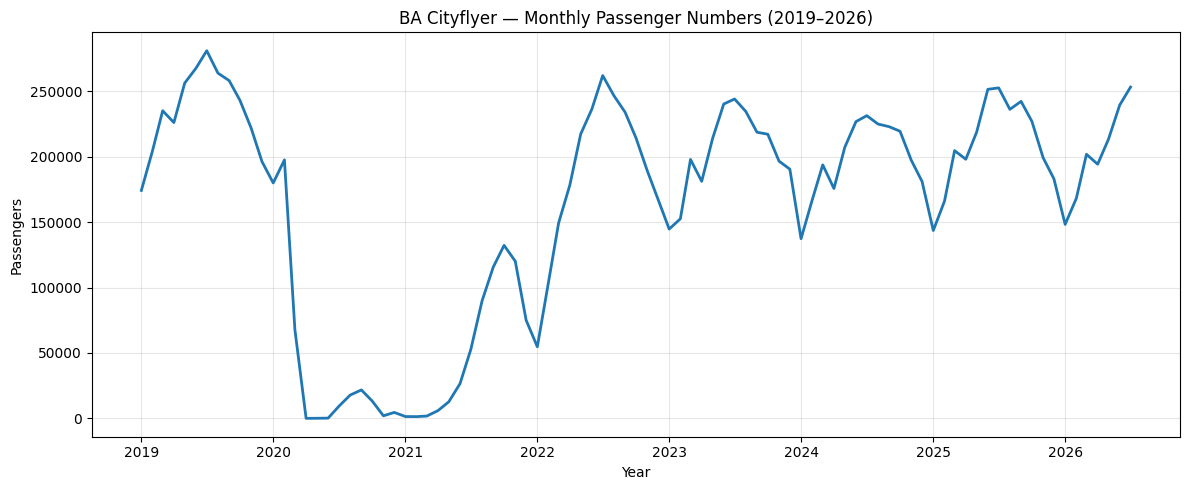

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(
    cityflyer["date"],
    cityflyer["total_passengers_uplifted"],
    linewidth=2
)

plt.title("BA Cityflyer — Monthly Passenger Numbers (2019–2026)")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
forecast_data = cityflyer.loc[
    cityflyer["date"] >= "2023-01-01",
    ["date", "total_passengers_uplifted"]
].copy()

forecast_data = forecast_data.set_index("date")

forecast_data = forecast_data.rename(
    columns={"total_passengers_uplifted": "passengers"}
)

print("Observations:", len(forecast_data))
print("Start:", forecast_data.index.min())
print("End:", forecast_data.index.max())

display(forecast_data.head())

Observations: 43
Start: 2023-01-01 00:00:00
End: 2026-07-01 00:00:00


,passengers
date,
2023-01-01,144676
2023-02-01,152545
2023-03-01,197871
2023-04-01,181154
2023-05-01,213771


In [6]:
monthly_average = forecast_data.groupby(
    forecast_data.index.month
)["passengers"].mean()

monthly_average.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

display(monthly_average.round(0))

Jan    143456.0
Feb    163436.0
Mar    199516.0
Apr    187268.0
May    213259.0
Jun    239487.0
Jul    245286.0
Aug    231892.0
Sep    227950.0
Oct    221165.0
Nov    197717.0
Dec    184820.0
Name: passengers, dtype: float64

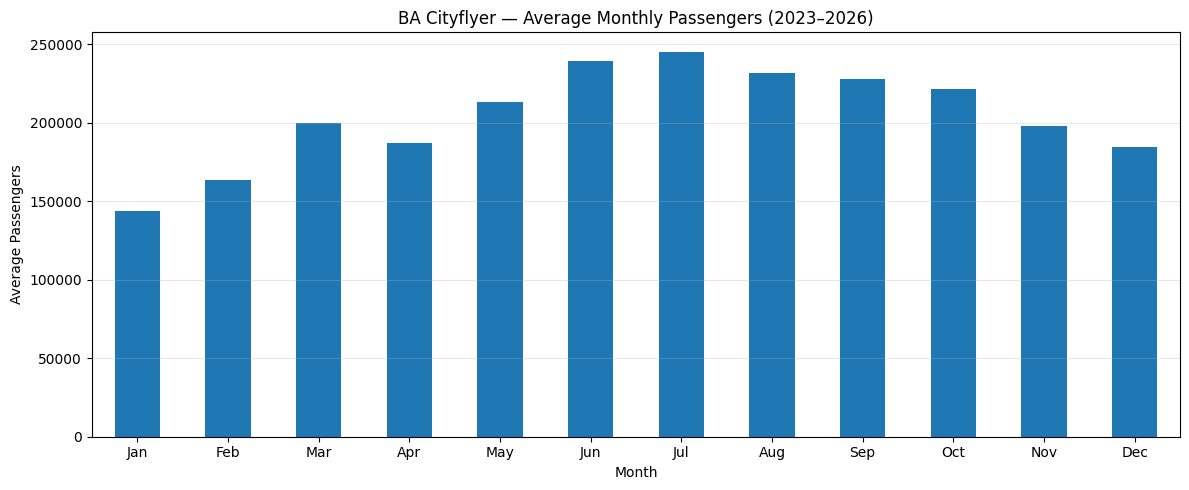

In [7]:
plt.figure(figsize=(12, 5))

monthly_average.plot(kind="bar")

plt.title("BA Cityflyer — Average Monthly Passengers (2023–2026)")
plt.xlabel("Month")
plt.ylabel("Average Passengers")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
train = forecast_data.loc[:"2025-12-01"].copy()
test = forecast_data.loc["2026-01-01":].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 36
Testing observations: 7
Training period: 2023-01-01 00:00:00 to 2025-12-01 00:00:00
Testing period: 2026-01-01 00:00:00 to 2026-07-01 00:00:00


In [9]:
seasonal_naive = train["passengers"].loc[
    "2025-01-01":"2025-07-01"
].copy()

seasonal_naive.index = test.index

comparison = pd.DataFrame({
    "Actual_2026": test["passengers"],
    "Forecast_2026": seasonal_naive
})

comparison["Error"] = (
    comparison["Actual_2026"] - comparison["Forecast_2026"]
)

display(comparison)

,Actual_2026,Forecast_2026,Error
date,,,
2026-01-01,148245,143586,4659
2026-02-01,168210,165961,2249
2026-03-01,201824,204622,-2798
2026-04-01,194242,198016,-3774
2026-05-01,213389,218750,-5361
2026-06-01,239444,251461,-12017
2026-07-01,253173,252578,595


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = comparison["Actual_2026"]
predicted = comparison["Forecast_2026"]

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(mean_squared_error(actual, predicted))

mape = np.mean(
    np.abs((actual - predicted) / actual)
) * 100

print(f"MAE: {mae:,.2f} passengers")
print(f"RMSE: {rmse:,.2f} passengers")
print(f"MAPE: {mape:.2f}%")

MAE: 4,493.29 passengers
RMSE: 5,635.84 passengers
MAPE: 2.23%


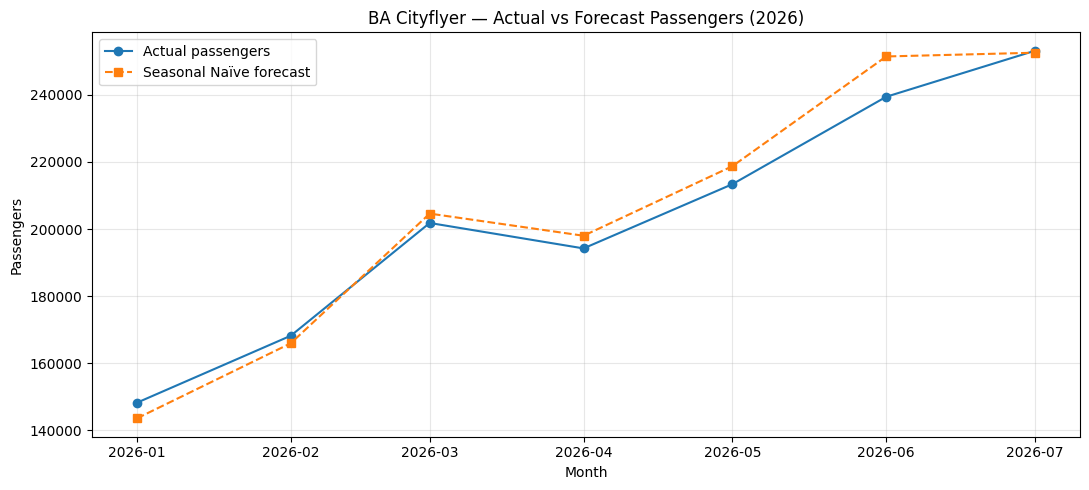

In [11]:
plt.figure(figsize=(11, 5))

plt.plot(
    comparison.index,
    comparison["Actual_2026"],
    marker="o",
    label="Actual passengers"
)

plt.plot(
    comparison.index,
    comparison["Forecast_2026"],
    marker="s",
    linestyle="--",
    label="Seasonal Naïve forecast"
)

plt.title("BA Cityflyer — Actual vs Forecast Passengers (2026)")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
regression_data = forecast_data.copy()

# Create a numerical time trend
regression_data["time"] = np.arange(len(regression_data))

# Extract the calendar month
regression_data["month"] = regression_data.index.month

display(regression_data.head())

,passengers,time,month
date,,,
2023-01-01,144676,0,1
2023-02-01,152545,1,2
2023-03-01,197871,2,3
2023-04-01,181154,3,4
2023-05-01,213771,4,5


In [13]:
month_dummies = pd.get_dummies(
    regression_data["month"],
    prefix="month",
    drop_first=True,
    dtype=int
)

regression_features = pd.concat(
    [regression_data[["time"]], month_dummies],
    axis=1
)

display(regression_features.head())

,time,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
date,,,,,,,,,,,,
2023-01-01,0,0,0,0,0,0,0,0,0,0,0,0
2023-02-01,1,1,0,0,0,0,0,0,0,0,0,0
2023-03-01,2,0,1,0,0,0,0,0,0,0,0,0
2023-04-01,3,0,0,1,0,0,0,0,0,0,0,0
2023-05-01,4,0,0,0,1,0,0,0,0,0,0,0


In [48]:
X_train = regression_features.loc[train.index]
X_test = regression_features.loc[test.index]

y_train = train["passengers"]
y_test = test["passengers"]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (36, 12)
Testing features: (7, 12)
Training target: (36,)
Testing target: (7,)


In [16]:
from sklearn.linear_model import LinearRegression

regression_model = LinearRegression()

regression_model.fit(X_train, y_train)

print("Seasonal regression model trained successfully.")

Seasonal regression model trained successfully.


In [17]:
regression_predictions = regression_model.predict(X_test)

regression_comparison = pd.DataFrame({
    "Actual_2026": y_test,
    "Regression_Forecast": regression_predictions
})

regression_comparison["Error"] = (
    regression_comparison["Actual_2026"]
    - regression_comparison["Regression_Forecast"]
)

display(regression_comparison.round(0))

,Actual_2026,Regression_Forecast,Error
date,,,
2026-01-01,148245,149428.0,-1183.0
2026-02-01,168210,169412.0,-1202.0
2026-03-01,201824,206315.0,-4491.0
2026-04-01,194242,192510.0,1732.0
2026-05-01,213389,220783.0,-7394.0
2026-06-01,239444,247069.0,-7625.0
2026-07-01,253173,250224.0,2949.0


In [18]:
regression_mae = mean_absolute_error(
    y_test, regression_predictions
)

regression_rmse = np.sqrt(
    mean_squared_error(y_test, regression_predictions)
)

regression_mape = np.mean(
    np.abs((y_test - regression_predictions) / y_test)
) * 100

print(f"Regression MAE: {regression_mae:,.2f} passengers")
print(f"Regression RMSE: {regression_rmse:,.2f} passengers")
print(f"Regression MAPE: {regression_mape:.2f}%")

Regression MAE: 3,796.61 passengers
Regression RMSE: 4,590.79 passengers
Regression MAPE: 1.78%


In [19]:
coefficients = pd.Series(
    regression_model.coef_,
    index=X_train.columns
)

print(f"Intercept: {regression_model.intercept_:,.2f}")

display(coefficients.round(2))

Intercept: 138,076.46


time          315.32
month_2     19669.01
month_3     56256.35
month_4     42136.36
month_5     70093.71
month_6     96064.72
month_7     98904.40
month_8     87824.07
month_9     83567.08
month_10    76467.09
month_11    52703.77
month_12    39490.78
dtype: float64

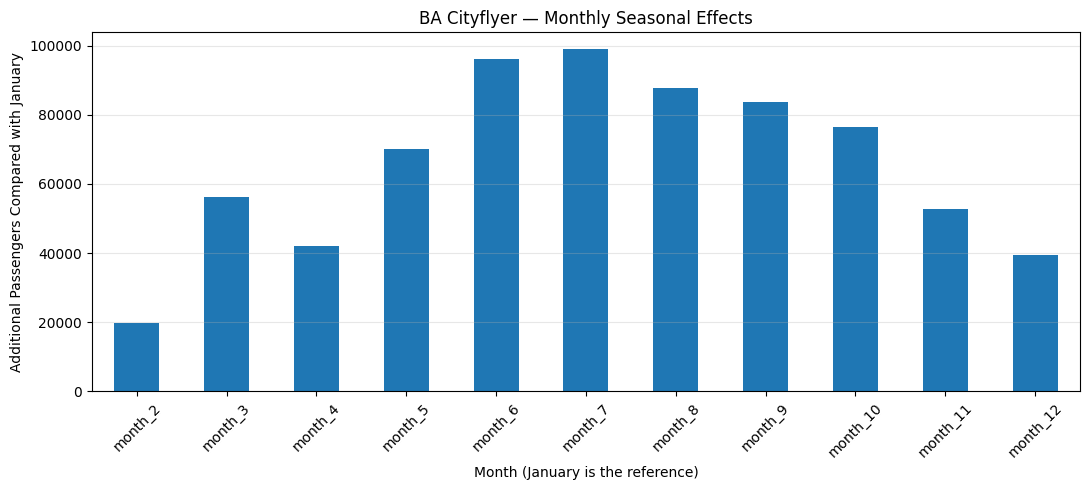

In [20]:
seasonal_coefficients = coefficients.drop("time")

plt.figure(figsize=(11, 5))

seasonal_coefficients.plot(kind="bar")

plt.title("BA Cityflyer — Monthly Seasonal Effects")
plt.xlabel("Month (January is the reference)")
plt.ylabel("Additional Passengers Compared with January")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [21]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

print("Exponential Smoothing imported successfully.")

Exponential Smoothing imported successfully.


In [49]:
hw_model = ExponentialSmoothing(
    train["passengers"],
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

print("Holt-Winters model configured successfully.")

Holt-Winters model configured successfully.


In [23]:
train.index = pd.DatetimeIndex(train.index, freq="MS")

print("Training data frequency:", train.index.freq)

Training data frequency: <MonthBegin>


In [25]:
hw_model = ExponentialSmoothing(
    train["passengers"],
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

hw_fitted = hw_model.fit()

print("Holt-Winters model trained successfully.")

Holt-Winters model trained successfully.


In [26]:
hw_predictions = hw_fitted.forecast(steps=7)

hw_comparison = pd.DataFrame({
    "Actual_2026": test["passengers"],
    "Holt_Winters_Forecast": hw_predictions
})

hw_comparison["Error"] = (
    hw_comparison["Actual_2026"]
    - hw_comparison["Holt_Winters_Forecast"]
)

display(hw_comparison.round(0))

,Actual_2026,Holt_Winters_Forecast,Error
2026-01-01,148245,142860.0,5385.0
2026-02-01,168210,168532.0,-322.0
2026-03-01,201824,201137.0,687.0
2026-04-01,194242,188177.0,6065.0
2026-05-01,213389,214295.0,-906.0
2026-06-01,239444,240734.0,-1290.0
2026-07-01,253173,243454.0,9719.0


In [27]:
hw_actual = hw_comparison["Actual_2026"]
hw_forecast = hw_comparison["Holt_Winters_Forecast"]

hw_mae = mean_absolute_error(hw_actual, hw_forecast)

hw_rmse = np.sqrt(
    mean_squared_error(hw_actual, hw_forecast)
)

hw_mape = np.mean(
    np.abs((hw_actual - hw_forecast) / hw_actual)
) * 100

print(f"Holt-Winters MAE: {hw_mae:,.2f} passengers")
print(f"Holt-Winters RMSE: {hw_rmse:,.2f} passengers")
print(f"Holt-Winters MAPE: {hw_mape:.2f}%")

Holt-Winters MAE: 3,481.85 passengers
Holt-Winters RMSE: 4,829.89 passengers
Holt-Winters MAPE: 1.73%


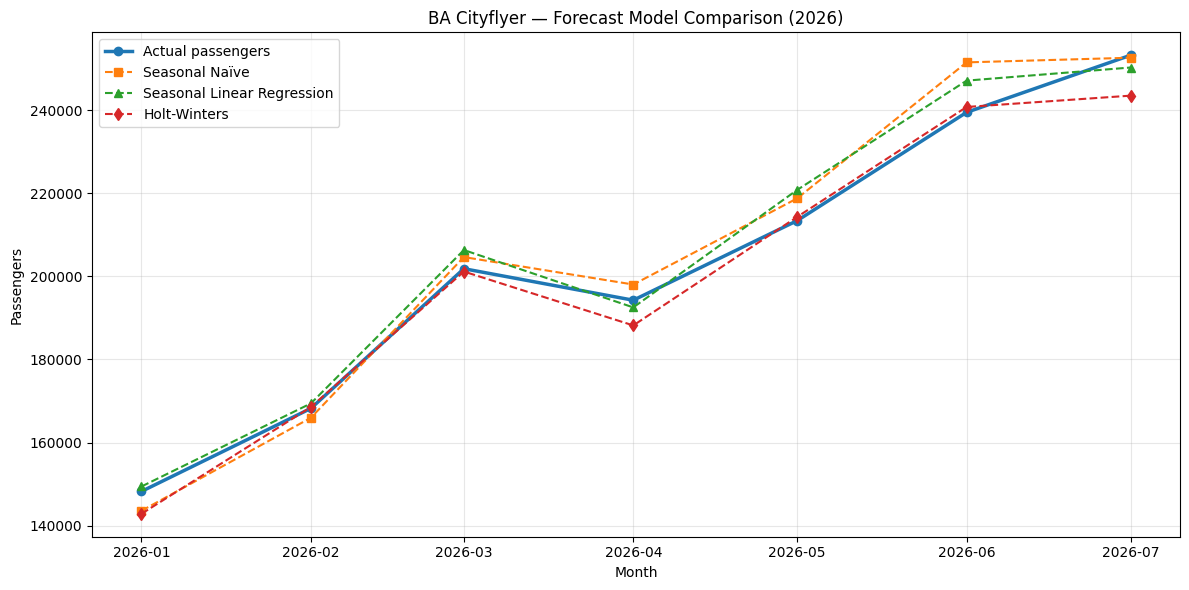

In [28]:
plt.figure(figsize=(12, 6))

plt.plot(
    test.index, test["passengers"],
    marker="o", linewidth=2.5,
    label="Actual passengers"
)

plt.plot(
    test.index, seasonal_naive,
    marker="s", linestyle="--",
    label="Seasonal Naïve"
)

plt.plot(
    test.index, regression_predictions,
    marker="^", linestyle="--",
    label="Seasonal Linear Regression"
)

plt.plot(
    test.index, hw_predictions,
    marker="d", linestyle="--",
    label="Holt-Winters"
)

plt.title("BA Cityflyer — Forecast Model Comparison (2026)")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [29]:
model_results = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "Seasonal Linear Regression",
        "Holt-Winters"
    ],
    "MAE": [mae, regression_mae, hw_mae],
    "RMSE": [rmse, regression_rmse, hw_rmse],
    "MAPE (%)": [mape, regression_mape, hw_mape]
})

model_results = model_results.sort_values("MAPE (%)")

display(model_results.round(2))

,Model,MAE,RMSE,MAPE (%)
2,Holt-Winters,3481.85,4829.89,1.73
1,Seasonal Linear Regression,3796.61,4590.79,1.78
0,Seasonal Naive,4493.29,5635.84,2.23


In [30]:
year_counts = forecast_data.groupby(
    forecast_data.index.year
).size()

print("Monthly observations by year:")
print(year_counts)

Monthly observations by year:
date
2023    12
2024    12
2025    12
2026     7
dtype: int64


In [31]:
backtest_train = forecast_data.loc[
    "2023-01-01":"2024-12-01"
].copy()

backtest_test = forecast_data.loc[
    "2025-01-01":"2025-07-01"
].copy()

print("Training observations:", len(backtest_train))
print("Testing observations:", len(backtest_test))

print("Training period:",
      backtest_train.index.min(),
      "to",
      backtest_train.index.max())

print("Testing period:",
      backtest_test.index.min(),
      "to",
      backtest_test.index.max())

Training observations: 24
Testing observations: 7
Training period: 2023-01-01 00:00:00 to 2024-12-01 00:00:00
Testing period: 2025-01-01 00:00:00 to 2025-07-01 00:00:00


In [32]:
backtest_naive = backtest_train["passengers"].loc[
    "2024-01-01":"2024-07-01"
].copy()

backtest_naive.index = backtest_test.index

backtest_naive_comparison = pd.DataFrame({
    "Actual_2025": backtest_test["passengers"],
    "Forecast_2025": backtest_naive
})

backtest_naive_comparison["Error"] = (
    backtest_naive_comparison["Actual_2025"]
    - backtest_naive_comparison["Forecast_2025"]
)

display(backtest_naive_comparison)

,Actual_2025,Forecast_2025,Error
date,,,
2025-01-01,143586,137319,6267
2025-02-01,165961,167028,-1067
2025-03-01,204622,193749,10873
2025-04-01,198016,175658,22358
2025-05-01,218750,207125,11625
2025-06-01,251461,226809,24652
2025-07-01,252578,231333,21245


In [33]:
bt_actual = backtest_naive_comparison["Actual_2025"]
bt_predicted = backtest_naive_comparison["Forecast_2025"]

bt_naive_mae = mean_absolute_error(bt_actual, bt_predicted)

bt_naive_rmse = np.sqrt(
    mean_squared_error(bt_actual, bt_predicted)
)

bt_naive_mape = np.mean(
    np.abs((bt_actual - bt_predicted) / bt_actual)
) * 100

print(f"2025 Seasonal Naïve MAE: {bt_naive_mae:,.2f}")
print(f"2025 Seasonal Naïve RMSE: {bt_naive_rmse:,.2f}")
print(f"2025 Seasonal Naïve MAPE: {bt_naive_mape:.2f}%")

2025 Seasonal Naïve MAE: 14,012.43
2025 Seasonal Naïve RMSE: 16,268.85
2025 Seasonal Naïve MAPE: 6.45%


In [34]:
bt_X_train = regression_features.loc[backtest_train.index]
bt_X_test = regression_features.loc[backtest_test.index]

bt_y_train = backtest_train["passengers"]
bt_y_test = backtest_test["passengers"]

print("Training features:", bt_X_train.shape)
print("Testing features:", bt_X_test.shape)

print("Training targets:", bt_y_train.shape)
print("Testing targets:", bt_y_test.shape)

Training features: (24, 12)
Testing features: (7, 12)
Training targets: (24,)
Testing targets: (7,)


In [35]:
bt_regression_model = LinearRegression()

bt_regression_model.fit(bt_X_train, bt_y_train)

print("Backtest Linear Regression model trained successfully.")

Backtest Linear Regression model trained successfully.


In [36]:
bt_regression_predictions = bt_regression_model.predict(bt_X_test)

bt_regression_comparison = pd.DataFrame({
    "Actual_2025": bt_y_test,
    "Regression_Forecast": bt_regression_predictions
})

bt_regression_comparison["Error"] = (
    bt_regression_comparison["Actual_2025"]
    - bt_regression_comparison["Regression_Forecast"]
)

display(bt_regression_comparison.round(2))

,Actual_2025,Regression_Forecast,Error
date,,,
2025-01-01,143586,135103.5,8482.5
2025-02-01,165961,153892.5,12068.5
2025-03-01,204622,189916.0,14706.0
2025-04-01,198016,172512.0,25504.0
2025-05-01,218750,204554.0,14196.0
2025-06-01,251461,227628.0,23833.0
2025-07-01,252578,231802.0,20776.0


In [37]:
bt_regression_mae = mean_absolute_error(
    bt_y_test, bt_regression_predictions
)

bt_regression_rmse = np.sqrt(
    mean_squared_error(bt_y_test, bt_regression_predictions)
)

bt_regression_mape = np.mean(
    np.abs(
        (bt_y_test - bt_regression_predictions) / bt_y_test
    )
) * 100

print(f"2025 Regression MAE: {bt_regression_mae:,.2f}")
print(f"2025 Regression RMSE: {bt_regression_rmse:,.2f}")
print(f"2025 Regression MAPE: {bt_regression_mape:.2f}%")

2025 Regression MAE: 17,080.86
2025 Regression RMSE: 18,069.32
2025 Regression MAPE: 8.21%


In [40]:
bt_hw_train = backtest_train["passengers"].copy()
bt_hw_train.index = pd.DatetimeIndex(
    bt_hw_train.index, freq="MS"
)

bt_hw_model = ExponentialSmoothing(
    bt_hw_train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

bt_hw_fitted = bt_hw_model.fit()

print("2025 Holt-Winters backtest model trained successfully.")

2025 Holt-Winters backtest model trained successfully.


In [41]:
bt_hw_predictions = bt_hw_fitted.forecast(steps=7)

bt_hw_comparison = pd.DataFrame({
    "Actual_2025": backtest_test["passengers"],
    "Holt_Winters_Forecast": bt_hw_predictions
})

bt_hw_comparison["Error"] = (
    bt_hw_comparison["Actual_2025"]
    - bt_hw_comparison["Holt_Winters_Forecast"]
)

display(bt_hw_comparison.round(2))

,Actual_2025,Holt_Winters_Forecast,Error
2025-01-01,143586,135101.33,8484.67
2025-02-01,165961,153891.95,12069.05
2025-03-01,204622,189917.92,14704.08
2025-04-01,198016,172511.95,25504.05
2025-05-01,218750,204554.50,14195.50
2025-06-01,251461,227622.57,23838.43
2025-07-01,252578,231802.10,20775.90


In [42]:
bt_hw_actual = bt_hw_comparison["Actual_2025"]
bt_hw_forecast = bt_hw_comparison["Holt_Winters_Forecast"]

bt_hw_mae = mean_absolute_error(
    bt_hw_actual, bt_hw_forecast
)

bt_hw_rmse = np.sqrt(
    mean_squared_error(bt_hw_actual, bt_hw_forecast)
)

bt_hw_mape = np.mean(
    np.abs((bt_hw_actual - bt_hw_forecast) / bt_hw_actual)
) * 100

print(f"2025 Holt-Winters MAE: {bt_hw_mae:,.2f}")
print(f"2025 Holt-Winters RMSE: {bt_hw_rmse:,.2f}")
print(f"2025 Holt-Winters MAPE: {bt_hw_mape:.2f}%")

2025 Holt-Winters MAE: 17,081.67
2025 Holt-Winters RMSE: 18,070.26
2025 Holt-Winters MAPE: 8.21%


In [43]:
backtest_results = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "Seasonal Linear Regression",
        "Holt-Winters"
    ],
    "2025 MAE": [
        bt_naive_mae,
        bt_regression_mae,
        bt_hw_mae
    ],
    "2025 RMSE": [
        bt_naive_rmse,
        bt_regression_rmse,
        bt_hw_rmse
    ],
    "2025 MAPE (%)": [
        bt_naive_mape,
        bt_regression_mape,
        bt_hw_mape
    ],
    "2026 MAE": [
        mae,
        regression_mae,
        hw_mae
    ],
    "2026 RMSE": [
        rmse,
        regression_rmse,
        hw_rmse
    ],
    "2026 MAPE (%)": [
        mape,
        regression_mape,
        hw_mape
    ]
})

display(backtest_results.round(2))

,Model,2025 MAE,2025 RMSE,2025 MAPE (%),2026 MAE,2026 RMSE,2026 MAPE (%)
0,Seasonal Naive,14012.43,16268.85,6.45,4493.29,5635.84,2.23
1,Seasonal Linear Regression,17080.86,18069.32,8.21,3796.61,4590.79,1.78
2,Holt-Winters,17081.67,18070.26,8.21,3481.85,4829.89,1.73


In [44]:
final_train = forecast_data["passengers"].copy()

final_train.index = pd.DatetimeIndex(
    final_train.index,
    freq="MS"
)

final_hw_model = ExponentialSmoothing(
    final_train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

final_hw_fitted = final_hw_model.fit()

print("Final Holt-Winters model trained successfully.")
print("Training observations:", len(final_train))
print("Last training month:", final_train.index.max())

Final Holt-Winters model trained successfully.
Training observations: 43
Last training month: 2026-07-01 00:00:00


In [45]:
final_hw_forecast = final_hw_fitted.forecast(steps=5)

final_forecast_df = pd.DataFrame({
    "Forecast_Passengers": final_hw_forecast
})

final_forecast_df.index.name = "Month"

display(final_forecast_df.round(0))

,Forecast_Passengers
Month,
2026-08-01,239654.0
2026-09-01,230951.0
2026-10-01,227965.0
2026-11-01,206413.0
2026-12-01,195033.0


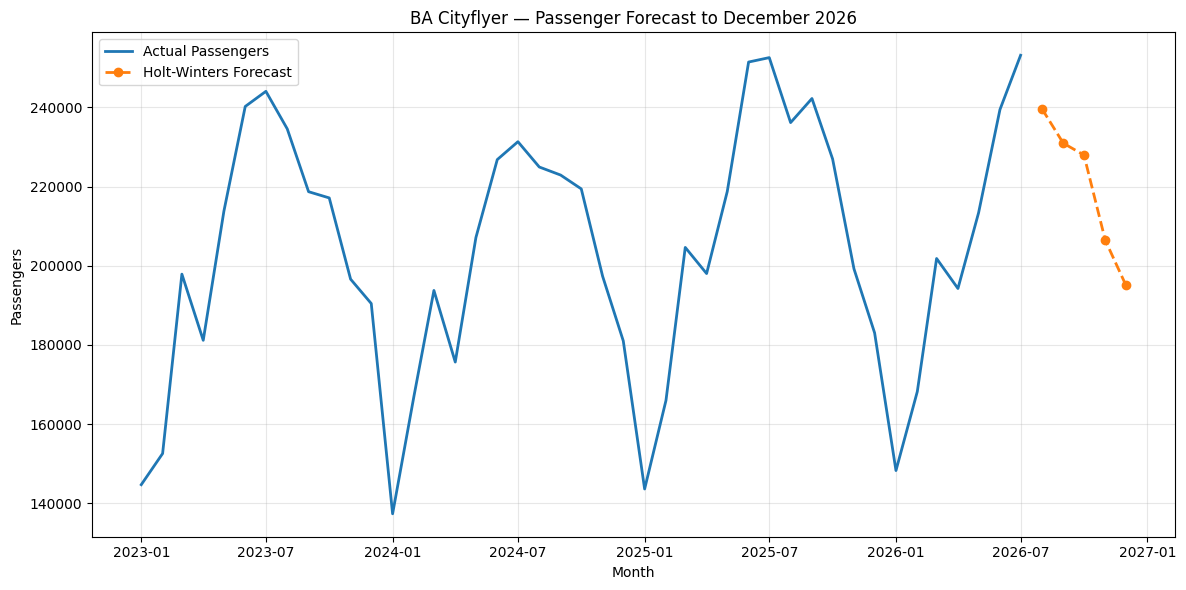

In [46]:
plt.figure(figsize=(12, 6))

plt.plot(
    forecast_data.index,
    forecast_data["passengers"],
    label="Actual Passengers",
    linewidth=2
)

plt.plot(
    final_hw_forecast.index,
    final_hw_forecast,
    label="Holt-Winters Forecast",
    linestyle="--",
    marker="o",
    linewidth=2
)

plt.title("BA Cityflyer — Passenger Forecast to December 2026")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

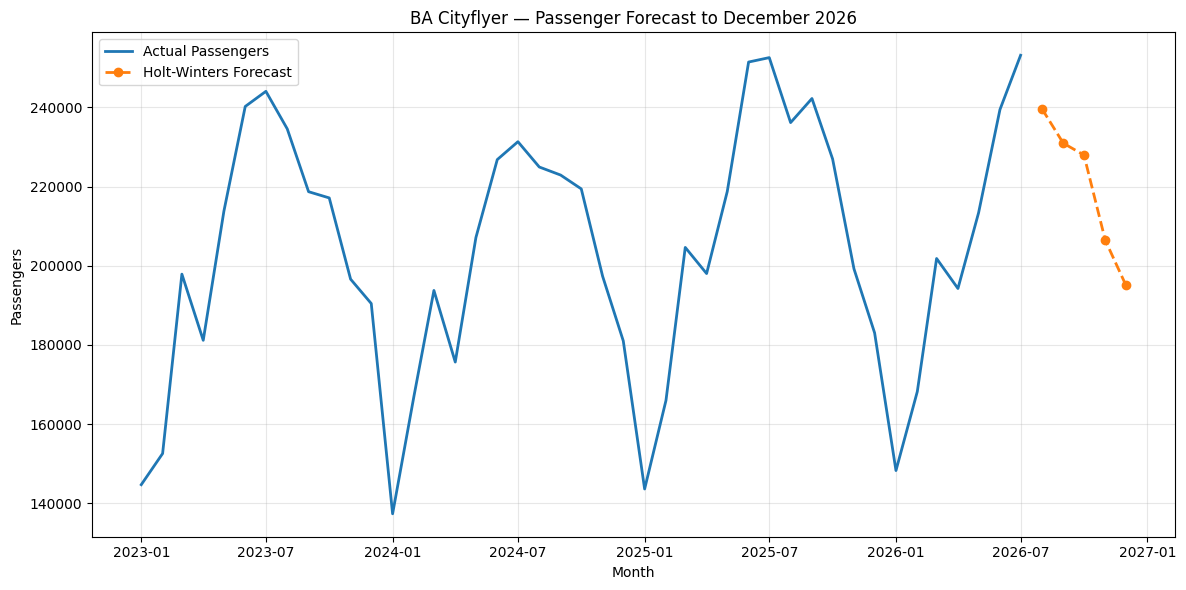

Forecast chart saved successfully.


In [47]:
from pathlib import Path

Path("reports/figures").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(12, 6))

plt.plot(
    forecast_data.index,
    forecast_data["passengers"],
    label="Actual Passengers",
    linewidth=2
)

plt.plot(
    final_hw_forecast.index,
    final_hw_forecast,
    label="Holt-Winters Forecast",
    linestyle="--",
    marker="o",
    linewidth=2
)

plt.title("BA Cityflyer — Passenger Forecast to December 2026")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "reports/figures/ba_cityflyer_passenger_forecast_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Forecast chart saved successfully.")


## Conclusions and Business Insights

### Forecasting performance

Three forecasting methods were evaluated: Seasonal Naïve, Seasonal Linear Regression and Holt-Winters.

Two historical test periods were used:

- January–July 2025
- January–July 2026

Seasonal Naïve achieved the lowest MAPE in 2025 (6.45%), while Holt-Winters achieved the lowest MAPE in 2026 (1.73%).

These results demonstrate that forecasting performance can vary between periods.

### Passenger demand forecast

The final Holt-Winters model was trained using 43 monthly observations from January 2023 to July 2026.

It forecasts approximately 1.10 million BA Cityflyer passengers between August and December 2026.

The forecast suggests a seasonal reduction in passenger demand towards the winter months.

### Commercial implications

These forecasts could support:

- Capacity and flight scheduling decisions.
- Seasonal resource planning.
- Passenger demand monitoring.
- Budgeting and revenue forecasting assumptions.

### Limitations

- Model validation covers only two seven-month periods.
- Historical patterns may not continue unchanged.
- External factors such as economic conditions, route changes and operational disruption are not included.
- The forecasts are point estimates without prediction intervals.
- Passenger forecasts should not be interpreted directly as revenue forecasts.

Future work could incorporate additional explanatory variables and longer historical validation periods.
